<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/statistical_field_theory/sft_colab_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Statistical Field Theory* — `sft_colab_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# SFT — Colab Visualizations
**Statistical Field Theory · Ch 1–4 · PSE Lab · Tong (Cambridge)**

Seven self-contained plot cells. Run each independently.

| Plot | Chapter | Topic |
|------|---------|-------|
| 1 | Ch 1 | Landau free energy: 2nd & 1st order transitions + Mexican hat |
| 2 | Ch 1 | Critical exponents: MFT vs 3D Ising |
| 3 | Ch 2 | Correlation functions: G(r), G(k), S(q) |
| 4 | Ch 3 | RG flow: beta function & flow diagram |
| 5 | Ch 3 | ε-expansion: ν, γ vs d; Rushbrooke check |
| 6 | Ch 4 | KT transition: vortex free energy, phase diagram, η(T) |
| 7 | Ch 4 | KT RG flow (K, y) & essential singularity of ξ |

---
## Plot 1 · Ch 1 — Landau Free Energy

**Left**: 2nd-order transition $F=a_2m^2+a_4m^4$. **Centre**: 1st-order with cubic $F=a_2m^2-cm^3+a_4m^4$. **Right**: Mexican hat $O(2)$ potential showing Goldstone direction.

  saved -> figures/sft/plot1_landau.png


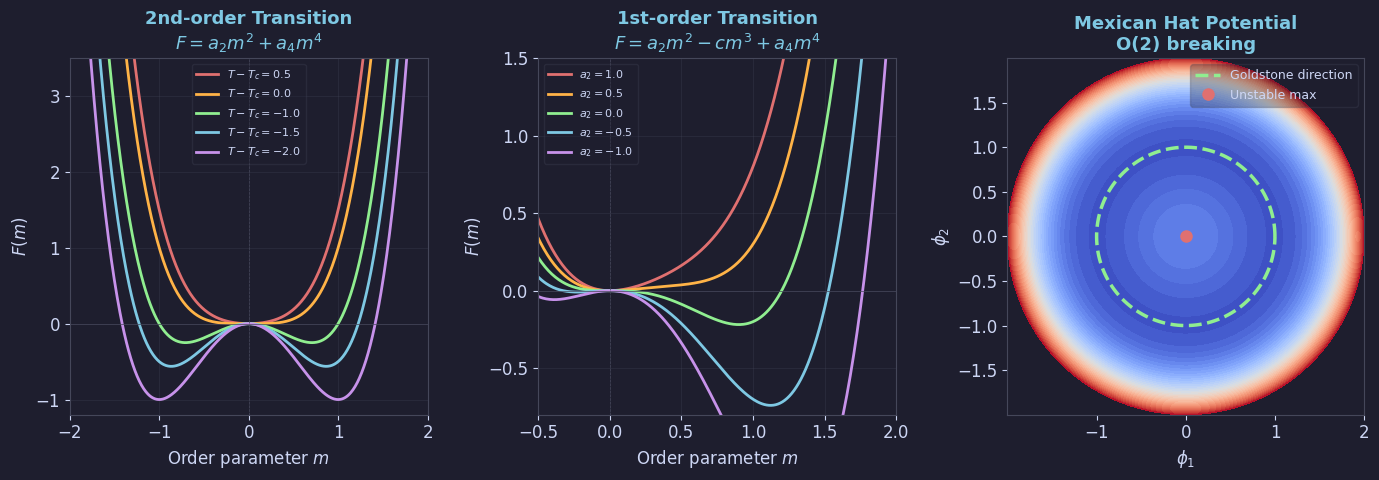

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.28,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/sft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 1: Landau Free Energy (Ch 1) ─────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)
m = np.linspace(-2.0, 2.0, 500)

ax = axes[0]
a4 = 1.0
for T, col in zip([1.5,1.0,0.0,-0.5,-1.0], [RED,ORANGE,GREEN,BLUE,PURPLE]):
    a2 = T - 1.0
    F = a2*m**2 + a4*m**4
    ax.plot(m, F, color=col, lw=2.0, label=f'$T-T_c={T-1:.1f}$')
ax.axhline(0, color=EDGE, lw=0.5); ax.axvline(0, color=EDGE, lw=0.5, ls='--')
ax.set_xlim(-2,2); ax.set_ylim(-1.2, 3.5)
ax.set_xlabel('Order parameter $m$'); ax.set_ylabel('$F(m)$')
ax.set_title('2nd-order Transition\n$F=a_2m^2+a_4m^4$', color=BLUE)
ax.legend(fontsize=8, labelcolor=FG, loc='upper center'); ax.grid(True)

ax2 = axes[1]
a4b, c = 1.0, 1.2
for T, col in zip([1.5,1.0,0.5,0.0,-0.5], [RED,ORANGE,GREEN,BLUE,PURPLE]):
    a2 = T - 0.5
    F = a2*m**2 - c*m**3 + a4b*m**4
    ax2.plot(m, F, color=col, lw=2.0, label=f'$a_2={a2:.1f}$')
ax2.axhline(0, color=EDGE, lw=0.5); ax2.axvline(0, color=EDGE, lw=0.5, ls='--')
ax2.set_xlim(-0.5, 2.0); ax2.set_ylim(-0.8, 1.5)
ax2.set_xlabel('Order parameter $m$'); ax2.set_ylabel('$F(m)$')
ax2.set_title('1st-order Transition\n$F=a_2m^2-cm^3+a_4m^4$', color=BLUE)
ax2.legend(fontsize=8, labelcolor=FG); ax2.grid(True)

ax3 = axes[2]
phi = np.linspace(0, 2*np.pi, 300)
r_v = np.linspace(0, 2, 100)
R, PHI = np.meshgrid(r_v, phi)
X = R*np.cos(PHI); Y = R*np.sin(PHI); V = -0.5*R**2 + 0.25*R**4
ax3.contourf(X, Y, V, levels=40, cmap='coolwarm')
ax3.plot(np.cos(phi), np.sin(phi), color=GREEN, lw=2.5, ls='--', label='Goldstone direction')
ax3.plot([0],[0], 'o', color=RED, ms=8, label='Unstable max')
ax3.set_aspect('equal')
ax3.set_xlabel(r'$\phi_1$'); ax3.set_ylabel(r'$\phi_2$')
ax3.set_title('Mexican Hat Potential\nO(2) breaking', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG)

plt.tight_layout(pad=1.2)
save('plot1_landau.png', fig)


---
## Plot 2 · Ch 1 — Critical Exponents

Mean field ($\beta=1/2$, $\gamma=1$, $\nu=1/2$) vs 3D Ising exact ($\beta=0.326$, $\gamma=1.237$, $\nu=0.630$). MFT fails for $d<4$.

  saved -> figures/sft/plot2_critexp.png


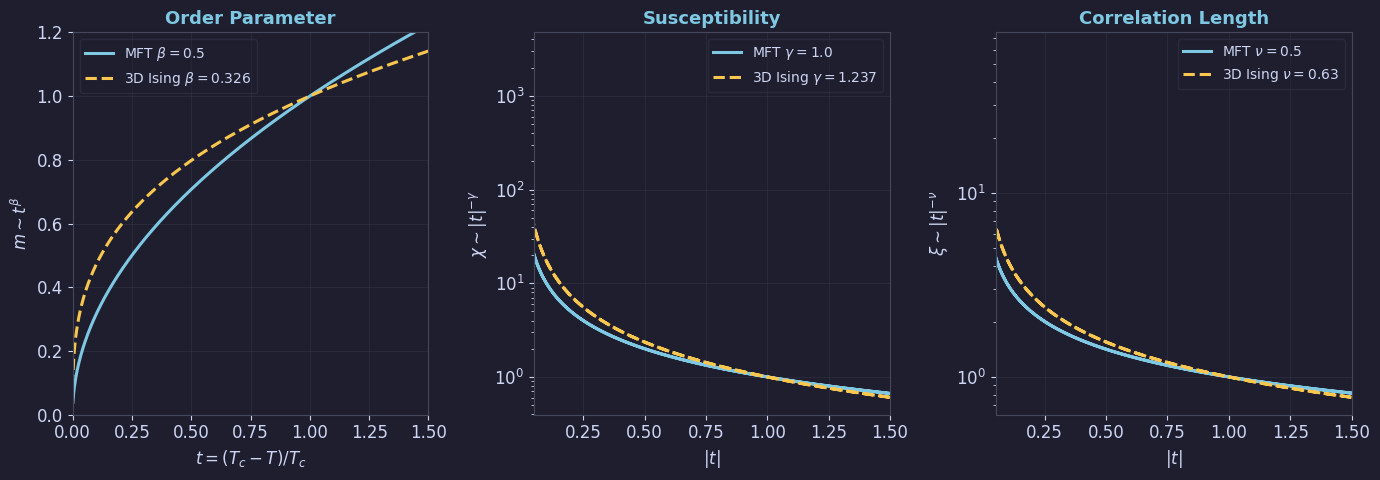

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.28,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/sft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 2: Critical Exponents (Ch 1) ─────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

t = np.linspace(-1.5, 1.5, 1000)
t_neg = t[t < 0]
beta_mf, gamma_mf, nu_mf = 0.5, 1.0, 0.5
beta_3d, gamma_3d, nu_3d = 0.326, 1.237, 0.630

ax = axes[0]
ax.plot(-t_neg, (-t_neg)**beta_mf, color=BLUE, lw=2.2, label=f'MFT $\\beta={beta_mf}$')
ax.plot(-t_neg, (-t_neg)**beta_3d, color=YELLOW, lw=2.2, ls='--',
        label=f'3D Ising $\\beta={beta_3d}$')
ax.set_xlabel('$t=(T_c-T)/T_c$'); ax.set_ylabel('$m\\sim t^\\beta$')
ax.set_title('Order Parameter', color=BLUE)
ax.legend(fontsize=10, labelcolor=FG); ax.grid(True)
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.2)

ax2 = axes[1]
t_pos = np.abs(t[1:])
ax2.semilogy(t_pos, t_pos**(-gamma_mf), color=BLUE, lw=2.2,
             label=f'MFT $\\gamma={gamma_mf}$')
ax2.semilogy(t_pos, t_pos**(-gamma_3d), color=YELLOW, lw=2.2, ls='--',
             label=f'3D Ising $\\gamma={gamma_3d}$')
ax2.set_xlabel('$|t|$'); ax2.set_ylabel('$\\chi\\sim|t|^{-\\gamma}$')
ax2.set_title('Susceptibility', color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0.05, 1.5)

ax3 = axes[2]
ax3.semilogy(t_pos, t_pos**(-nu_mf), color=BLUE, lw=2.2, label=f'MFT $\\nu={nu_mf}$')
ax3.semilogy(t_pos, t_pos**(-nu_3d), color=YELLOW, lw=2.2, ls='--',
             label=f'3D Ising $\\nu={nu_3d}$')
ax3.set_xlabel('$|t|$'); ax3.set_ylabel('$\\xi\\sim|t|^{-\\nu}$')
ax3.set_title('Correlation Length', color=BLUE)
ax3.legend(fontsize=10, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(0.05, 1.5)

plt.tight_layout(pad=1.2)
save('plot2_critexp.png', fig)


---
## Plot 3 · Ch 2 — Correlation Functions

**Left**: $G(r)$ real-space decay. **Centre**: Propagator $G(k)=(k^2+\mu^2)^{-1}$. **Right**: Ornstein-Zernike structure factor $S(q)$.

  saved -> figures/sft/plot3_corrfn.png


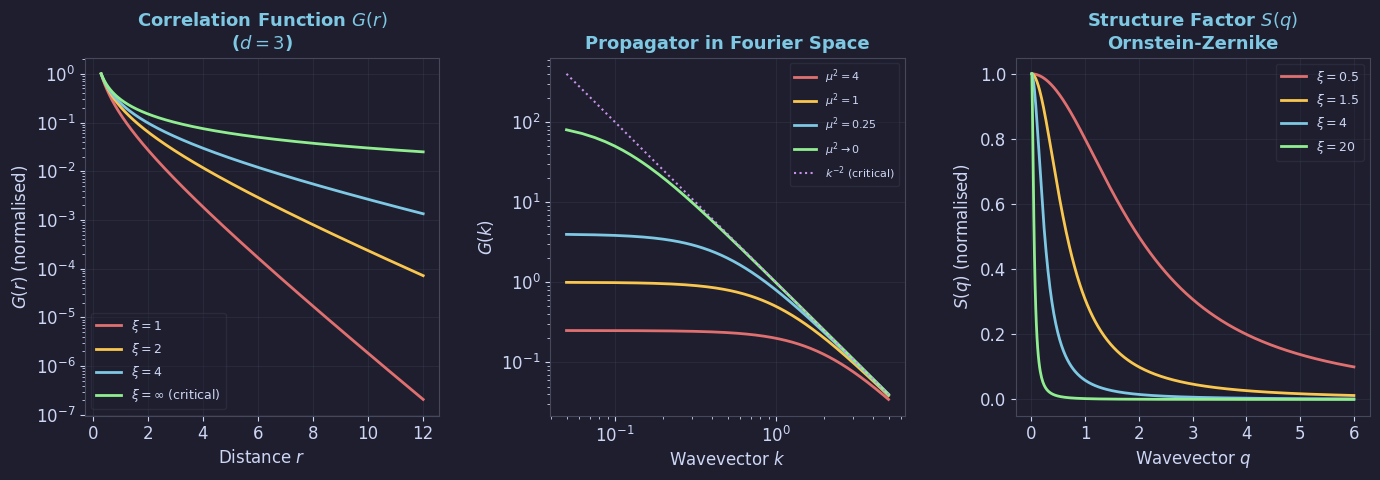

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.28,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/sft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 3: Correlation Functions (Ch 2) ───────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)
r = np.linspace(0.3, 12, 500)

ax = axes[0]
for xi, col, lab in [(1.0,RED,'$\\xi=1$'),(2.0,YELLOW,'$\\xi=2$'),
                      (4.0,BLUE,'$\\xi=4$')]:
    G = np.exp(-r/xi)/r; G /= G[0]
    ax.semilogy(r, G, color=col, lw=2.0, label=lab)
G_crit = r**(-1); G_crit /= G_crit[0]
ax.semilogy(r, G_crit, color=GREEN, lw=2.0, label='$\\xi=\\infty$ (critical)')
ax.set_xlabel('Distance $r$'); ax.set_ylabel('$G(r)$ (normalised)')
ax.set_title('Correlation Function $G(r)$\n($d=3$)', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)

ax2 = axes[1]
k = np.linspace(0.05, 5, 400)
for mu2, col, lab in [(4.0,RED,'$\\mu^2=4$'),(1.0,YELLOW,'$\\mu^2=1$'),
                       (0.25,BLUE,'$\\mu^2=0.25$'),(0.01,GREEN,'$\\mu^2\\to0$')]:
    Gk = 1.0/(k**2 + mu2)
    ax2.loglog(k, Gk, color=col, lw=2.0, label=lab)
ax2.loglog(k, k**(-2), color=PURPLE, lw=1.5, ls=':', label='$k^{-2}$ (critical)')
ax2.set_xlabel('Wavevector $k$'); ax2.set_ylabel('$G(k)$')
ax2.set_title('Propagator in Fourier Space', color=BLUE)
ax2.legend(fontsize=8, labelcolor=FG); ax2.grid(True)

ax3 = axes[2]
q = np.linspace(0.01, 6, 500)
for xi_v, col, lab in [(0.5,RED,'$\\xi=0.5$'),(1.5,YELLOW,'$\\xi=1.5$'),
                        (4.0,BLUE,'$\\xi=4$'),(20.0,GREEN,'$\\xi=20$')]:
    Sq = xi_v**2 / (1 + (q*xi_v)**2)
    ax3.plot(q, Sq/Sq.max(), color=col, lw=2.0, label=lab)
ax3.set_xlabel('Wavevector $q$'); ax3.set_ylabel('$S(q)$ (normalised)')
ax3.set_title('Structure Factor $S(q)$\nOrnstein-Zernike', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)

plt.tight_layout(pad=1.2)
save('plot3_corrfn.png', fig)


---
## Plot 4 · Ch 3 — RG Flow

**Left**: Beta function $\beta(g)=\epsilon g-Cg^2$ showing Gaussian FP (unstable) and Wilson-Fisher FP (stable). **Right**: Flow diagram in $(t,g)$ space.

  saved -> figures/sft/plot4_rgflow.png


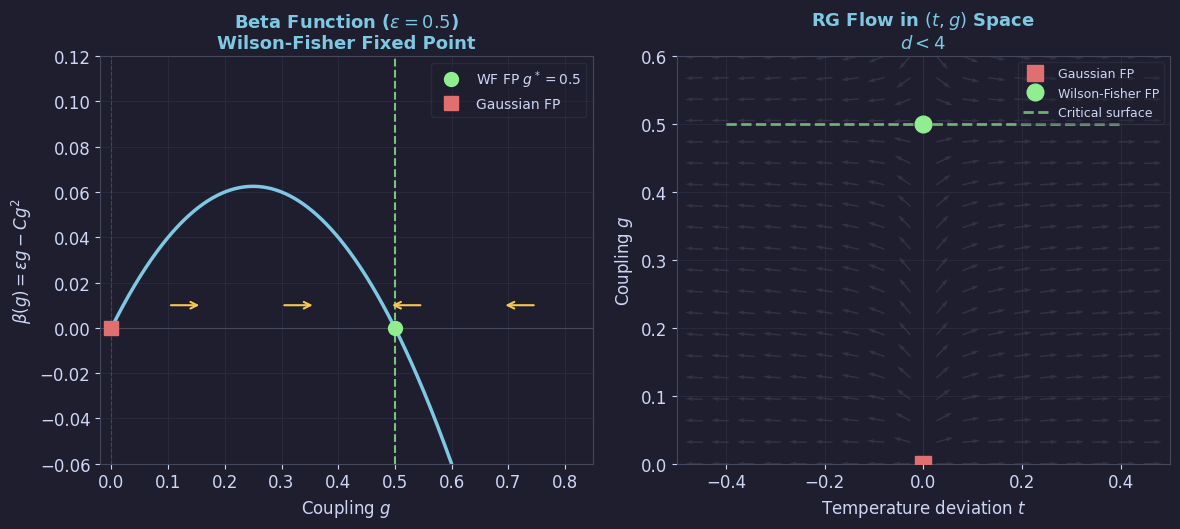

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.28,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/sft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 4: RG Flow (Ch 3) ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.patch.set_facecolor(BG)

g_arr = np.linspace(0, 0.8, 400)
epsilon, C = 0.5, 1.0
beta_g = epsilon*g_arr - C*g_arr**2
g_star = epsilon/C

ax = axes[0]
ax.plot(g_arr, beta_g, color=BLUE, lw=2.5)
ax.axhline(0, color=EDGE, lw=0.8); ax.axvline(0, color=EDGE, lw=0.8, ls='--')
ax.axvline(g_star, color=GREEN, lw=1.5, ls='--', alpha=0.8)
ax.plot([g_star],[0], 'o', color=GREEN, ms=10, zorder=5, label=f'WF FP $g^*={g_star}$')
ax.plot([0],[0], 's', color=RED, ms=10, zorder=5, label='Gaussian FP')
for g0, dx in [(0.1,0.06),(0.3,0.06),(0.55,-0.06),(0.75,-0.06)]:
    ax.annotate('', xy=(g0+dx, 0.01), xytext=(g0, 0.01),
                arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.5, mutation_scale=12))
ax.set_xlabel('Coupling $g$'); ax.set_ylabel('$\\beta(g)=\\epsilon g-Cg^2$')
ax.set_title(f'Beta Function ($\\epsilon={epsilon}$)\nWilson-Fisher Fixed Point', color=BLUE)
ax.legend(fontsize=10, labelcolor=FG); ax.grid(True)
ax.set_xlim(-0.02, 0.85); ax.set_ylim(-0.06, 0.12)

t_grid = np.linspace(-0.5, 0.5, 20)
g_grid = np.linspace(0.0, 0.6, 20)
T_g, G_g = np.meshgrid(t_grid, g_grid)
dt = 2.0*T_g; dg = 0.5*G_g - G_g**2
mag = np.sqrt(dt**2 + dg**2) + 1e-10

ax2 = axes[1]
ax2.quiver(T_g, G_g, dt/mag, dg/mag, color=EDGE, alpha=0.5, scale=28, width=0.003)
ax2.plot([0],[0], 's', color=RED, ms=12, zorder=5, label='Gaussian FP')
ax2.plot([0],[0.5], 'o', color=GREEN, ms=12, zorder=5, label='Wilson-Fisher FP')
t_cs = np.linspace(-0.4, 0.4, 100)
ax2.plot(t_cs, 0.5*np.ones_like(t_cs), color=GREEN, lw=2.0, ls='--',
         alpha=0.7, label='Critical surface')
ax2.axvline(0, color=EDGE, lw=0.5, ls=':'); ax2.axhline(0, color=EDGE, lw=0.5)
ax2.set_xlabel('Temperature deviation $t$'); ax2.set_ylabel('Coupling $g$')
ax2.set_title('RG Flow in $(t,g)$ Space\n$d<4$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG)
ax2.set_xlim(-0.5, 0.5); ax2.set_ylim(0, 0.6); ax2.grid(True)

plt.tight_layout(pad=1.2)
save('plot4_rgflow.png', fig)


---
## Plot 5 · Ch 3 — ε-Expansion

Critical exponents $\nu$, $\gamma$ as functions of $d=4-\epsilon$. Leading-order results compared to exact 3D values. Rushbrooke relation $\alpha+2\beta+\gamma=2$ verified.

  saved -> figures/sft/plot5_epsilon.png


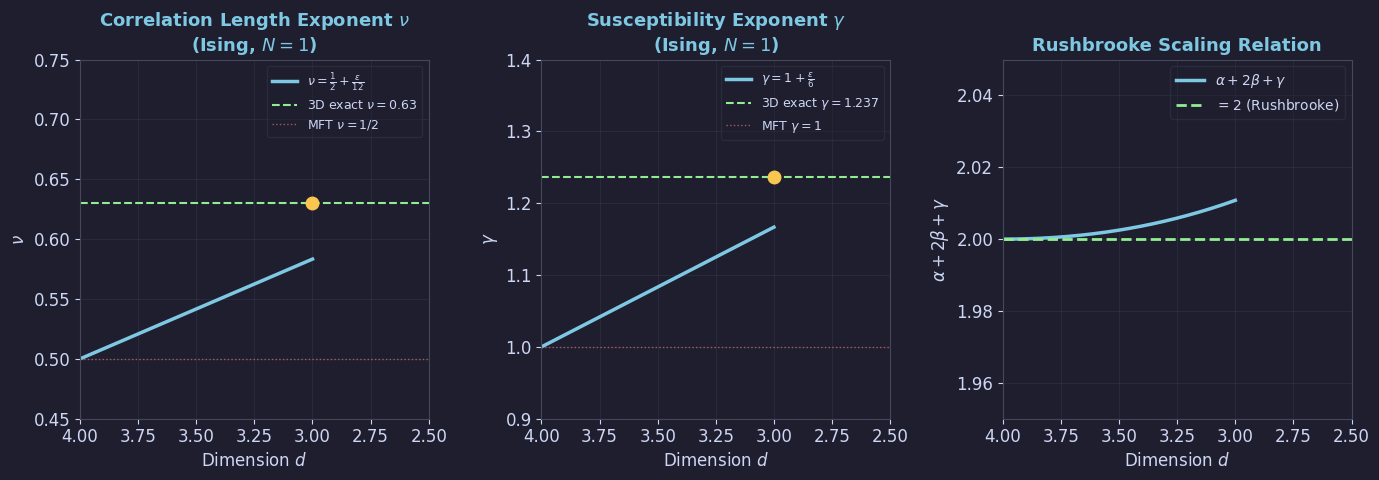

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.28,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/sft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 5: ε-Expansion (Ch 3) ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

eps = np.linspace(0, 1.0, 200)
d = 4 - eps
nu_eps = 0.5 + eps/12
gamma_eps = 1 + eps/6
nu_3d_exact = 0.630; gamma_3d_exact = 1.237

ax = axes[0]
ax.plot(d, nu_eps, color=BLUE, lw=2.5, label='$\\nu=\\frac{1}{2}+\\frac{\\epsilon}{12}$')
ax.axhline(nu_3d_exact, color=GREEN, lw=1.5, ls='--', label=f'3D exact $\\nu={nu_3d_exact}$')
ax.axhline(0.5, color=RED, lw=1.0, ls=':', alpha=0.7, label='MFT $\\nu=1/2$')
ax.plot([3],[nu_3d_exact], 'o', color=YELLOW, ms=9, zorder=5)
ax.set_xlabel('Dimension $d$'); ax.set_ylabel('$\\nu$')
ax.set_title('Correlation Length Exponent $\\nu$\n(Ising, $N=1$)', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(2.5, 4.0); ax.set_ylim(0.45, 0.75); ax.invert_xaxis()

ax2 = axes[1]
ax2.plot(d, gamma_eps, color=BLUE, lw=2.5, label='$\\gamma=1+\\frac{\\epsilon}{6}$')
ax2.axhline(gamma_3d_exact, color=GREEN, lw=1.5, ls='--',
            label=f'3D exact $\\gamma={gamma_3d_exact}$')
ax2.axhline(1.0, color=RED, lw=1.0, ls=':', alpha=0.7, label='MFT $\\gamma=1$')
ax2.plot([3],[gamma_3d_exact], 'o', color=YELLOW, ms=9, zorder=5)
ax2.set_xlabel('Dimension $d$'); ax2.set_ylabel('$\\gamma$')
ax2.set_title('Susceptibility Exponent $\\gamma$\n(Ising, $N=1$)', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(2.5, 4.0); ax2.set_ylim(0.9, 1.4); ax2.invert_xaxis()

eta_eps = eps**2/54
alpha_eps = 2 - d*nu_eps
beta_eps = nu_eps*(d-2+eta_eps)/2
rushbrooke = alpha_eps + 2*beta_eps + gamma_eps
ax3 = axes[2]
ax3.plot(d, rushbrooke, color=BLUE, lw=2.5, label='$\\alpha+2\\beta+\\gamma$')
ax3.axhline(2.0, color=GREEN, lw=2.0, ls='--', label='$=2$ (Rushbrooke)')
ax3.set_xlabel('Dimension $d$'); ax3.set_ylabel('$\\alpha+2\\beta+\\gamma$')
ax3.set_title('Rushbrooke Scaling Relation', color=BLUE)
ax3.legend(fontsize=10, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(2.5, 4.0); ax3.set_ylim(1.95, 2.05); ax3.invert_xaxis()

plt.tight_layout(pad=1.2)
save('plot5_epsilon.png', fig)


---
## Plot 6 · Ch 4 — KT Transition

**Left**: Vortex free energy $F_v=(\pi J-2T)\ln L$. **Centre**: Superfluid stiffness with universal jump. **Right**: Anomalous dimension $\eta(T)=T/2\pi J$.

  saved -> figures/sft/plot6_kt.png


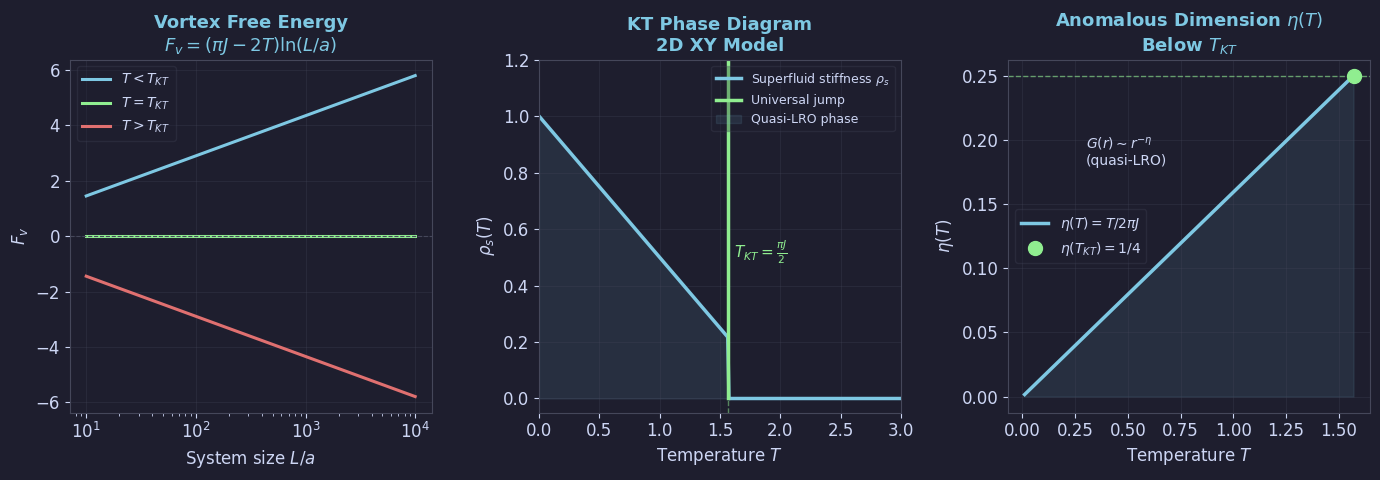

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.28,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/sft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 6: KT Transition (Ch 4) ───────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

J = 1.0
T_KT = np.pi*J/2
L_vals = np.logspace(1, 4, 200)
E_v = np.pi*J*np.log(L_vals)

ax = axes[0]
for T_val, col, lab in [(0.8*T_KT,BLUE,'$T<T_{KT}$'),
                         (T_KT,GREEN,'$T=T_{KT}$'),
                         (1.2*T_KT,RED,'$T>T_{KT}$')]:
    S_v = 2*T_val*np.log(L_vals)
    ax.semilogx(L_vals, E_v-S_v, color=col, lw=2.2, label=lab)
ax.axhline(0, color=EDGE, lw=0.8, ls='--')
ax.set_xlabel('System size $L/a$'); ax.set_ylabel('$F_v$')
ax.set_title('Vortex Free Energy\n$F_v=(\\pi J-2T)\\ln(L/a)$', color=BLUE)
ax.legend(fontsize=10, labelcolor=FG); ax.grid(True)

ax2 = axes[1]
T_arr = np.linspace(0, 3, 300)
rho_below = J*(1-T_arr/(2*J)); rho_below = np.maximum(rho_below, 0)
rho_below[T_arr > T_KT] = 0
ax2.plot(T_arr, rho_below, color=BLUE, lw=2.5, label='Superfluid stiffness $\\rho_s$')
ax2.plot([T_KT,T_KT],[0,np.pi*T_KT/2], color=GREEN, lw=2.5,
         label='Universal jump')
ax2.axvline(T_KT, color=GREEN, lw=1.0, ls='--', alpha=0.5)
ax2.text(T_KT+0.05, 0.5, r'$T_{KT}=\frac{\pi J}{2}$', color=GREEN, fontsize=11)
ax2.fill_between(T_arr[T_arr<T_KT], 0, rho_below[T_arr<T_KT],
                 color=BLUE, alpha=0.1, label='Quasi-LRO phase')
ax2.set_xlabel('Temperature $T$'); ax2.set_ylabel('$\\rho_s(T)$')
ax2.set_title('KT Phase Diagram\n2D XY Model', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0, 3); ax2.set_ylim(-0.05, 1.2)

ax3 = axes[2]
T_below = np.linspace(0.01, T_KT, 200)
eta_T = T_below/(2*np.pi*J)
ax3.plot(T_below, eta_T, color=BLUE, lw=2.5, label=r'$\eta(T)=T/2\pi J$')
ax3.plot([T_KT],[1/4], 'o', color=GREEN, ms=10, zorder=5,
         label='$\\eta(T_{KT})=1/4$')
ax3.axhline(1/4, color=GREEN, lw=1.0, ls='--', alpha=0.6)
ax3.fill_between(T_below, 0, eta_T, color=BLUE, alpha=0.1)
ax3.text(0.3, 0.18, '$G(r)\\sim r^{-\\eta}$\n(quasi-LRO)', color=FG, fontsize=10)
ax3.set_xlabel('Temperature $T$'); ax3.set_ylabel('$\\eta(T)$')
ax3.set_title('Anomalous Dimension $\\eta(T)$\nBelow $T_{KT}$', color=BLUE)
ax3.legend(fontsize=10, labelcolor=FG); ax3.grid(True)

plt.tight_layout(pad=1.2)
save('plot6_kt.png', fig)


---
## Plot 7 · Ch 4 — KT RG Flow & Essential Singularity

**Left**: RG flow in $(K,y)$ space — KT fixed point at $K_c=2/\pi$, $y=0$. **Right**: Correlation length $\xi\sim e^{b/\sqrt{t}}$ (essential singularity) vs power law.

  saved -> figures/sft/plot7_kt_rg.png


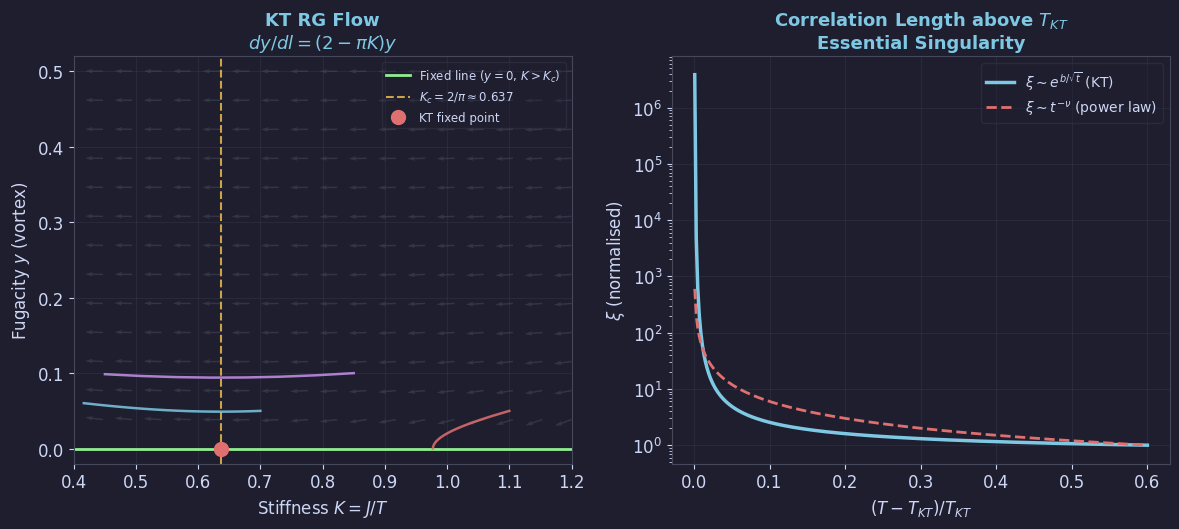

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.28,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/sft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 7: KT RG Flow & Essential Singularity (Ch 4) ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.patch.set_facecolor(BG)

K_vals = np.linspace(0.4, 1.2, 18)
y_vals = np.linspace(0.0, 0.5, 14)
K_g, Y_g = np.meshgrid(K_vals, y_vals)
dK = -4*np.pi**3*Y_g**2
dy = (2 - np.pi*K_g)*Y_g
mag = np.sqrt(dK**2 + dy**2) + 1e-10

ax = axes[0]
ax.quiver(K_g, Y_g, dK/mag, dy/mag, color=EDGE, alpha=0.55, scale=28, width=0.003)
K_crit = 2/np.pi
ax.axhline(0, color=GREEN, lw=2.0, label='Fixed line ($y=0$, $K>K_c$)')
ax.axvline(K_crit, color=YELLOW, lw=1.5, ls='--', alpha=0.8,
           label=f'$K_c=2/\\pi\\approx{K_crit:.3f}$')
ax.plot([K_crit],[0], 'o', color=RED, ms=10, zorder=5, label='KT fixed point')

def rg_eqs(l, state):
    K, y = state
    return [-4*np.pi**3*y**2, (2-np.pi*K)*y]

for K0, y0, col in [(0.7,0.05,BLUE),(0.85,0.1,PURPLE),
                     (0.6,0.2,ORANGE),(1.1,0.05,RED)]:
    sol = solve_ivp(rg_eqs, [0,15], [K0,y0], max_step=0.1, dense_output=True)
    l_arr = np.linspace(0, 15, 300)
    traj = sol.sol(l_arr)
    mask = (traj[0]>0.4)&(traj[0]<1.2)&(traj[1]>=0)&(traj[1]<0.55)
    ax.plot(traj[0][mask], traj[1][mask], color=col, lw=1.8, alpha=0.85)

ax.set_xlabel('Stiffness $K=J/T$'); ax.set_ylabel('Fugacity $y$ (vortex)')
ax.set_title('KT RG Flow\n$dy/dl=(2-\\pi K)y$', color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG)
ax.set_xlim(0.4, 1.2); ax.set_ylim(-0.02, 0.52); ax.grid(True)

J = 1.0; T_KT = np.pi*J/2
T_above = np.linspace(T_KT*1.001, T_KT*1.6, 300)
t_kt = (T_above-T_KT)/T_KT
xi_kt = np.exp(0.5/np.sqrt(t_kt)); xi_kt /= xi_kt[-1]
xi_pow = t_kt**(-1.0); xi_pow /= xi_pow[-1]

ax2 = axes[1]
ax2.semilogy(T_above/T_KT-1, xi_kt, color=BLUE, lw=2.5,
             label=r'$\xi\sim e^{b/\sqrt{t}}$ (KT)')
ax2.semilogy(T_above/T_KT-1, xi_pow, color=RED, lw=2.0, ls='--',
             label=r'$\xi\sim t^{-\nu}$ (power law)')
ax2.set_xlabel('$(T-T_{KT})/T_{KT}$'); ax2.set_ylabel('$\\xi$ (normalised)')
ax2.set_title('Correlation Length above $T_{KT}$\nEssential Singularity', color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG); ax2.grid(True)

plt.tight_layout(pad=1.2)
save('plot7_kt_rg.png', fig)


---
## Download All Figures

In [8]:
import os, zipfile
from google.colab import files

OUTDIR = 'figures/sft'
saved = sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')]) if os.path.exists(OUTDIR) else []
print(f"Found {len(saved)} figures:")
for f in saved:
    print(f"  {f}  ({os.path.getsize(f'{OUTDIR}/{f}')//1024} KB)")

zip_name = 'sft_colab_visualizations.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in saved:
        zf.write(f'{OUTDIR}/{fname}', arcname=fname)

print(f'\nZip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 7 figures:
  plot1_landau.png  (299 KB)
  plot2_critexp.png  (128 KB)
  plot3_corrfn.png  (241 KB)
  plot4_rgflow.png  (220 KB)
  plot5_epsilon.png  (116 KB)
  plot6_kt.png  (167 KB)
  plot7_kt_rg.png  (172 KB)

Zip: sft_colab_visualizations.zip  (1274 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>